# Auditory attention of non-native English speakers: statistical analysis and a lang2vec extension

**Alexa García Nuñez**

Analysis of the PhyAAt tabular dataset (auditory attention scores under different noise, length and semantic conditions), followed by an original extension testing whether the linguistic distance between participants' first language and English predicts attention.


*Reminder: You will be focusing on auditory conditions and attention scores, not on physiological signals.*

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[5 marks]</b></span>
    
#### Task 1. Summary of the experiment


Write a short paragraph explaining the experiment and data collection (**maximum of 300 words**). 
</div>

<br>
<span style="float:left;color:gray;font-size:20px">Descriptive Statistics</span>
<br>
<br>

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[20 marks]</b></span>
    
#### Task 2. Summarise the collected dataset 
<!-- [20 marks] -->

Download the two data files described above and summarise the dataset. Recall and apply the methods covered in descriptive statistics to explore, analyse, and summarise the data. Hint: Descriptive statistics include measures of central tendency and variability, frequency tables, proportions, probability distributions, and visualisations such as histograms, box-and-whisker plots, pie charts, and bar charts.

**Select appropriate measures and visualisations, and write a report explaining your findings** (*refer to the marking criteria*).

</div>

### Task 1

The PhyAAt experiment assessed how auditory and linguistic factors impact the attention of non-native English speakers in a simulated e-learning environment [2]. It involved 25 healthy university students from various nationalities whose first language was not English [2].

Each participant completed a listening task where they heard English sentences and transcribed them as accurately as possible. Researchers sourced 5,000 English audio clips from the Tatoeba Project [4], selecting sentences between 3 and 13 words recorded by a single male speaker to ensure consistent pitch and speech rate. From these, 1,700 non-semantic clips were generated by inserting isolated words into otherwise meaningful sentences.

Three independent variables were manipulated to create 36 distinct experimental conditions. The first is semanticity: 0 = semantic and 1 = non-semantic. The second is stimulus length, categorised by number of words into Small (L1), Medium (L2), and Long (L3). The third is noise level, with six levels of background noise ranging from SNR=−6dB (very noisy) to SNR=1000dB (noise-free).

Each participant completed 144 trials, each consisting of three phases: listening, transcribing, and resting. The interface was disabled between trials to prevent distraction and participants could not replay audio.

Attention score was calculated as the number of correctly transcribed words divided by the total words in the sentence, multiplied by 100. Minor spelling errors were ignored to focus on auditory perception rather than writing ability [2]. Scores were then averaged across participants for each experimental condition to analyse the impact of noise, length, and semanticity.

Physiological signals including EEG and PPG were also recorded, with the long-term goal of correlating physiological responses with attention scores to build adaptive e-learning systems [3]. However this assignment focuses exclusively on the tabular attention score and demographic data.

### Task 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import spkit as sp
import scipy
import warnings
warnings.filterwarnings('ignore')

Top 5 Conditions by Mean Attention Score:


,Condition,mean,std
0,32. 1000dB | S=0 | L2,86.48,17.25
1,31. 1000dB | S=0 | L1,85.17,16.10
2,33. 1000dB | S=0 | L3,72.80,22.48
3,25. 6dB | S=0 | L1,72.04,21.34
4,34. 1000dB | S=1 | L1,67.03,17.78



Bottom 5 Conditions by Mean Attention Score:


,Condition,mean,std
0,4. -6dB | S=1 | L1,10.41,9.74
1,5. -6dB | S=1 | L2,8.21,6.51
2,6. -6dB | S=1 | L3,6.91,7.10
3,2. -6dB | S=0 | L2,5.86,6.53
4,3. -6dB | S=0 | L3,4.84,6.74


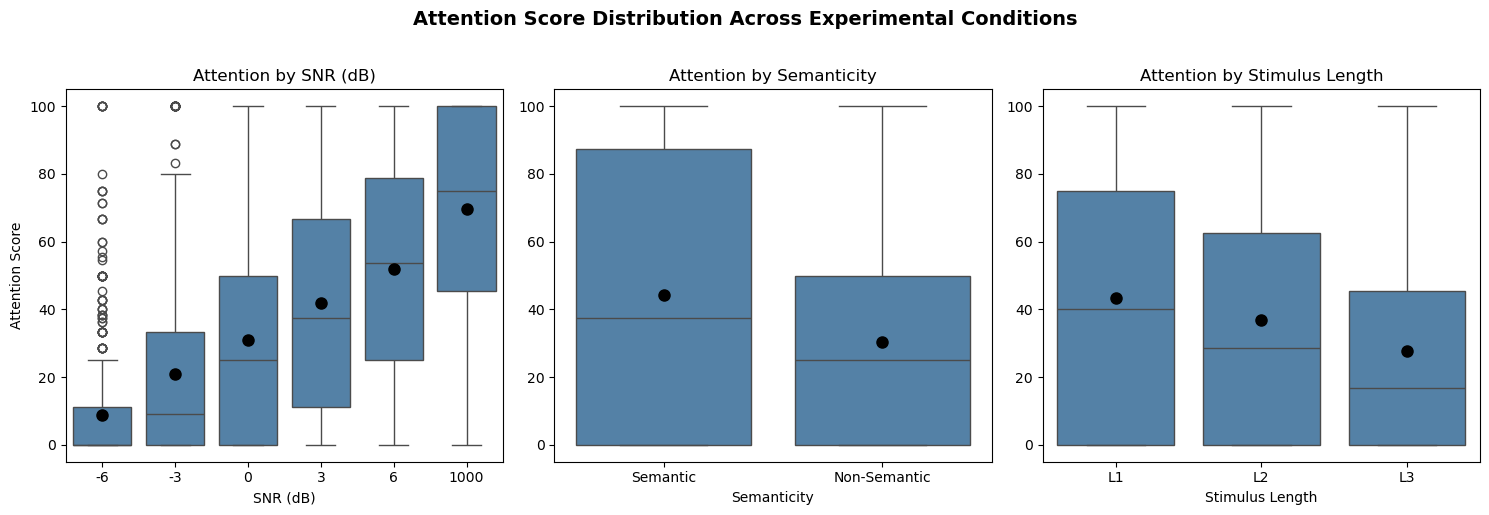

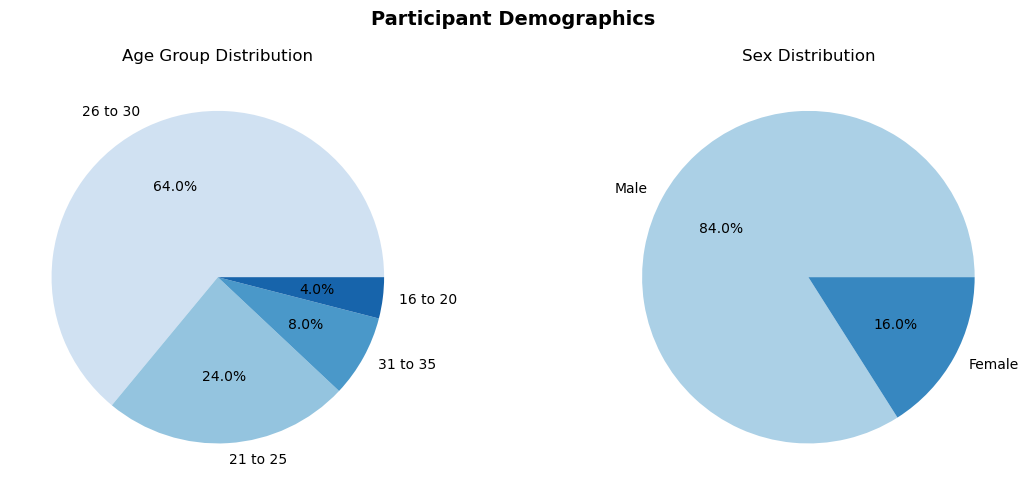

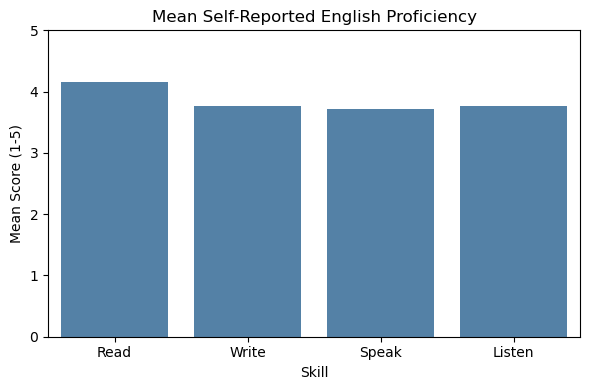

In [2]:
All_trial_data = pd.read_csv('PhyAAt_AttentionScore_AllTrials_v1 (1).csv')
AD = pd.DataFrame(All_trial_data)
Condensed_trial_data = pd.read_csv('PhyAAt_AttentionScoreData_v1 (1).csv')
CD = pd.DataFrame(Condensed_trial_data)
demographic_data = pd.read_csv('PhyAAt_Demographic_Rating_v1 (1).csv')
DD = pd.DataFrame(demographic_data)
CD_demo = pd.merge(CD, DD, on='SID')

CD.describe()
CD.groupby('SNRdB')['AttentionScore'].describe()
CD.groupby('Semanticity')['AttentionScore'].describe()
CD.groupby('LengthStim')['AttentionScore'].describe()

avg = CD.groupby(['SNRdB', 'Semanticity', 'LengthStim'])['AttentionScore'].describe().reset_index()
avg['Condition'] = [f"{i+1}. {row['SNRdB']}dB | S={int(row['Semanticity'])} | {row['LengthStim']}" 
                    for i, row in avg.iterrows()]
avg_sorted = avg.sort_values('mean', ascending=False)

print("Top 5 Conditions by Mean Attention Score:")
display(avg_sorted[['Condition', 'mean', 'std']].head().round(2).reset_index(drop=True))
print("\nBottom 5 Conditions by Mean Attention Score:")
display(avg_sorted[['Condition', 'mean', 'std']].tail().round(2).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
conditions = [
    ('SNRdB', 'SNR (dB)', [-6, -3, 0, 3, 6, 1000]),
    ('Semanticity', 'Semanticity', [0, 1]),
    ('LengthStim', 'Stimulus Length', ['L1', 'L2', 'L3'])
]
for ax, (col, xlabel, order) in zip(axes, conditions):
    sns.boxplot(data=AD, x=col, y='AttentionScore',
                order=order, color='steelblue', ax=ax,
                showmeans=True,
                meanprops={'marker':'o', 
                           'markerfacecolor':'black', 
                           'markeredgecolor':'black',
                           'markersize': 8})
    ax.set_title(f'Attention by {xlabel}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Attention Score' if ax == axes[0] else '')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Semantic', 'Non-Semantic'])
plt.suptitle('Attention Score Distribution Across Experimental Conditions',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
age_pct = DD['AgeGroup'].value_counts()
axes[0].pie(age_pct.values, labels=age_pct.index, autopct='%1.1f%%',
            colors=sns.color_palette('Blues', len(age_pct)))
axes[0].set_title('Age Group Distribution')
sex_pct = DD['Sex'].value_counts()
axes[1].pie(sex_pct.values, labels=sex_pct.index, autopct='%1.1f%%',
            colors=sns.color_palette('Blues', len(sex_pct)))
axes[1].set_title('Sex Distribution')
plt.suptitle('Participant Demographics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

lang_means = DD[['Read', 'Write', 'Speak', 'Listen']].mean()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=lang_means.index, y=lang_means.values, color='steelblue', ax=ax)
ax.set_title('Mean Self-Reported English Proficiency')
ax.set_xlabel('Skill')
ax.set_ylabel('Mean Score (1-5)')
ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()



For summarising the Data I created 3 charts each with multiple boxplots to represent the attention score distributions across the three experimental variables : noise level (SNRdB), semanticity, and stimulus length. I chose boxplots as they simultaneously display median, spread (IQR), and outliers, with the black dot indicating the mean. For the boxplots, I used the full trial dataset (AD) to preserve raw data and visualise variability of attentions scores within each condition across individual trials. For the descriptive summary table of top and bottom scoring conditions ( above the boxplots), I used the condensed dataset (CD), which contains attention scores pre averaged per participant per condition, giving a cleaner representation of central tendency per condition.

The boxplots and table reveal that attention scores increase consistently with reduced noise and shorter sentences, and are higher for semantic stimuli. This suggests patterns that meaningful sentences, low sound and shorter sentences really aid auditory attention, as expected. We can see that under high noise conditions the distribution is right skewed, with most participants scoring near zero and a few outliers pulling the mean upward. Under low noise conditions the distribution is more symmetric, with the mean lying close to the median, reflecting consistently higher and more evenly spread attention scores across participants.

I considered plotting attention scores per individual participant on a bar chart, however this produced 25 separate bars which added visual complexity without meaningful insight beyond what the condition boxplots already reveal. The three charts were therefore intentionally designed to represent the maximum amount of information in the most concise way possible.

In terms of demographic data we can see that the majority of participants over 60% are 26-30 years old and male. On average all participants self-professed English language level is relatively high however.








<span style="float:left;color:gray;font-size:20px">Inferential Statistics: Estimation</span>
<br>

<br>

Now that you have summarised the data and the experiment, you are ready to apply inferential statistics and move beyond the dataset (**sample**) to draw conclusions or make generalisations about the wider world (**population**).

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[10 marks]</b></span>

#### Task 3. Estimation
<!-- [10 marks] -->

Think about the population and estimate the average attention score along with a confidence interval. Explain your results.

* What is the population in this context?
* Select a specific experimental condition (e.g., noise-free semantic stimuli or noisey non-semantic stimuli). Hint: you may use any combination of experimental conditions.
* Estimate the average attention score and its confidence interval for the population.
* Explain your results and state your conclusions (**maximum 100 words**).

</div>

p-value: 0.0005229568199354896
Sample size: 25
Mean: 13.03
Standard Error: 2.8057
95% CI: (7.24, 18.82)


4      35.0
59      5.0
86      5.0
127     0.0
171    10.0
Name: AttentionScore, dtype: float64

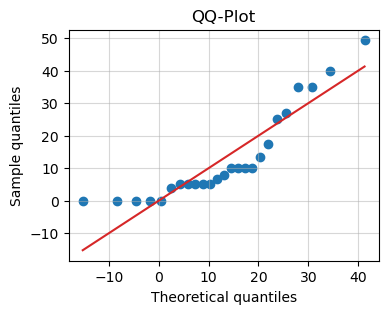

In [3]:
from scipy import stats
condition = CD[(CD['SNRdB']==-6) & (CD['Semanticity']==0) & (CD['LengthStim']=='L1')]['AttentionScore']
def QQplot(x):
    fig,ax = plt.subplots(1, figsize=(4,3))
    data_sorted = np.sort(x)
    n = len(data_sorted)
    p = (np.arange(1, n+1) - 0.5) / n
    theoretical = scipy.stats.norm.ppf(p)*data_sorted.std() + data_sorted.mean()
    plt.scatter(theoretical, data_sorted)
    plt.plot(theoretical, theoretical, color='C3')
    plt.xlabel("Theoretical quantiles")
    plt.ylabel("Sample quantiles")
    plt.title('QQ-Plot')
    plt.grid(alpha=0.5)
    
QQplot(condition)
t,p = scipy.stats.shapiro(condition)
print('p-value:', p)
mean = condition.mean()
standard_error = stats.sem(condition)
confidence_interval = stats.t.interval(0.95, df=len(condition)-1, loc=mean, scale=standard_error)
print(f"Sample size: {len(condition)}")
print(f"Mean: {mean:.2f}")
print(f"Standard Error: {standard_error :.4f}")
print(f"95% CI: ({confidence_interval[0]:.2f}, {confidence_interval [1]:.2f})")
condition.head()

I selected semantic, short (L1) sentences under the noisiest condition (SNR=−6dB). Using the condensed dataset (n=25, one score per participant per condition) ensures independence of observations. The population is defined as all healthy non-native English speaking university students e-learning under this condition. Since the population variance is unknown and n<30, a t-based 95% confidence interval was computed (SE=2.81), returning a mean of 13.03 with CI (7.24, 18.82). The wide interval reflects the small sample size. Shapiro-Wilk and QQ-plot indicate non-normality (p<0.001), so the t-interval should be interpreted as an approximation with caution (bootstrapping would be a more appropriate alternative).


.


<span style="float:left;color:gray;font-size:20px">Inferential Statistics: Hypothesis testing (comparing two groups)</span>
<br>
<br>

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[10 marks]</b></span>
    
#### Task 4. Compare two experimental conditions [this will be covered in lab]
<!-- [10 marks] -->

In this task, you will compare two experimental conditions to determine whether they are different from one another. 

**This is a guided task**, where each step is outlined to help you get started with hypothesis testing. Subsequent tasks related hypothesis testing will briefly described. Here are the steps:

* **Define your hypothesis clearly:**

    The attention level in a noisy environment $E_1$ is significantly different from that in a noiseless environment $E_2$ for short       semantic sentences.

    - Null Hypothesis        $H_0: $ $\mu_{E_1} = \mu_{E_2}$
    - Alternative Hypothesis $H_A: $ $\mu_{E_1} \ne \mu_{E_2}$
    <br>

* **Acquire the dataset:**

    Extract attention scores for the two specified experimental conditions $E_1$ and $E_2$:
    - $E_1$: Noisy environment (SNR = -6 dB), short stimuli (L1), and semantic sentences (S = 0)
    - $E_2$: Noiseless environment (SNR = 1000 dB), short stimuli (L1), and semantic sentences (S = 0)
      <br>
      
* **Explain the testing procedure:**

    - Is this paired or unpaired setting?
    - Choose an appropriate test: parametric (Student’s t-test) or non-parametric (Wilcoxon signed-rank test)
    - State any assumptions and perform additional checks if needed (e.g., normality, homogeneity of variance)
      <br>
  
* **Perform the test:** Compute the p-value and relevant test statistics.
* **Conclude your findings** with interpretation of the results and the effect size (**maximum 100 words**).
</div>

 Shapiro Wilk Test Statistic: 0.9436078114355951 
 Shapiro Wilk p-value: 0.17927123836033365
Paired t-test: -19.31625546167349 3.9380730407438357e-16
Since our Wilcoxon signed-rank test's p value is < 0.05, we reject the null hypothesis that μ_E1 = μ_E2 :the attention level in a noisy environment is the same of that in a noiseless environment for short semantic sentences.


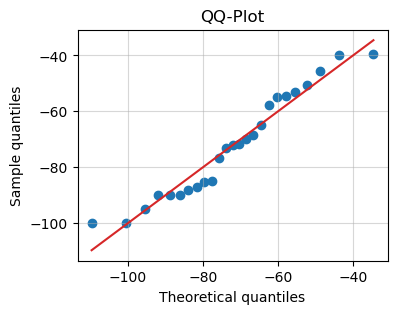

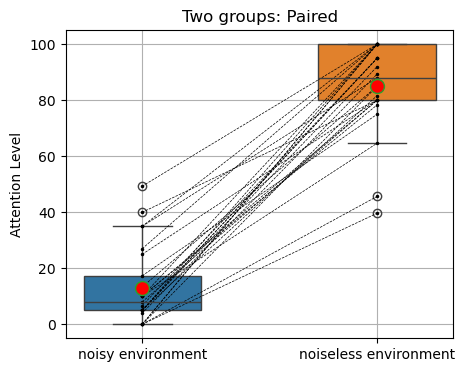

In [4]:
noisy_condition = CD[(CD['SNRdB']== -6) & (CD['LengthStim']=='L1') & (CD['Semanticity']==0)]
noiseless_condition = CD[(CD['SNRdB']==1000) & (CD['LengthStim']=='L1') & (CD['Semanticity']==0)]
noisy_avg = noisy_condition.set_index('SID')['AttentionScore']
noiseless_avg = noiseless_condition.set_index('SID')['AttentionScore']
H0= 'μ_E1 = μ_E2 :the attention level in a noisy environment is the same of that in a noiseless environment for short semantic sentences'
H1= 'μ_E1 ≠ μ_E2 :the attention level in a noisy environment is significantly different from that in a noiseless environment for short semantic sentences'
differences = noisy_avg.values - noiseless_avg.values
stat, p = stats.shapiro(differences)
print(' Shapiro Wilk Test Statistic:',stat, '\n', 'Shapiro Wilk p-value:', p)
QQplot(differences)
if p > 0.05:
    stat, p_val = stats.ttest_rel(noisy_avg, noiseless_avg)
    print("Paired t-test:", stat, p_val)
else:
    stat, p_val = stats.wilcoxon(noisy_avg, noiseless_avg)
    print("Wilcoxon signed-rank Test Statistic:", stat,'\n',"Wilcoxon signed-rank p value:", p_val)
if p_val < 0.05:
    print("Since our Wilcoxon signed-rank test's p value is < 0.05, we reject the null hypothesis that {0}.".format(H0))
else:
    print("Since our p value is > 0.05, we fail to reject the null hypothesis that {0}.".format(H0))
fig,ax = plt.subplots(1, figsize=(5,4))
sp.stats.plot_groups_boxes([noisy_avg,noiseless_avg], lines=True,
    xlabels=['noisy environment','noiseless environment'],ylab='Attention Level', title='Two groups: Paired',ax=ax)
plt.show()


H₀ states the attention level in a noisy environment equals that in a noiseless environment for short semantic sentences, H₁ states that they differ significantly. Since H₁ is 'different' and we are comparing the same people 25 participants under two conditions this is a paired two-tailed test. Shapiro-Wilk indicates normality so we use the paired t-test. The p-value is significantly < 0.05 so we reject the null hypothesis meaning that  attention under noise is significantly different from noiseless. The boxplot confirms this, with all lines sloping upward from noisy to noiseless, indicating every participant scored higher in the noiseless condition without exception.


<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[10 marks]</b></span>
    
#### Task 5. Compare two subjects 
<!-- [10 marks] -->

In this task, you will compare two subjects to determine whether they differ in terms of auditory attention skills.

Select two subjects based on your QMUL ID and denote them as $S_k$ and $S_p$.

* Define your hypothesis clearly
* Acquire the data corresponding to the two selected subjects
* Explain the testing procedure (paired or unpaired, parametric or non-parametric, choice of test, assumptions, and any additional tests)
* Perform the tests
* Conclude your findings (**maximum 100 words**)


**Select two subjects based on your QMUL ID[2 marks]**

To select two subjects, use the last four digits of your QMUL ID. Let the first two digits be denoted as $d_1$ and the last two digits as $d_2$. Then, use the following formula to compute $k$ and $p$.

```python
k = 1 + d1%25
p = 1 + d2%25
if p==k: p=p+1

```

This small piece of code will ensure the values of $k$ and $p$ are in range of 1 to 25 and not the same for all the QMUL IDs.

For example, if your QMUL ID is 250123456, then the last four digits are 3456 and $d1 = 34$ and $d2=56$. Using the above formula, you get value of $k$ and $p$ as follow:

$k = 1 + 34\%25 = 10$ and $p = 1 + 56\%25 = 7$, so your two subjects are $S_{10}$ and $S_7$


**NOTE: If you do not use your the correct subjects to compare you will loose 2 marks**

</div>

The two subjects compared here are subject 93 and subject 77.

In [5]:
d1 = 93
d2 = 77
k = 1 + d1%25
p = 1 + d2%25
if p==k: p=p+1

print('your students are s{0} and s{1}'.format(k, p))

s19 =  CD[CD['SID'] == 'S19']['AttentionScore']
s3 = CD[CD['SID'] == 'S3']['AttentionScore']

your students are s19 and s3


your students are s19 and s3
S19 Shapiro Wilk Test Statistic: 0.6368916645835272 
 S19 Shapiro Wilk p-value: 3.299652513484005e-08
S3 Shapiro Wilk Test Statistic: 0.9322194331915303 
 S3 Shapiro Wilk p-value: 0.02923828766836053
Mann-Whitney U Test Statistic: 217.0 
 Mann-Whitney U p value: 1.0220235615122673e-06
Since our p value is < 0.05, we reject the null hypothesis that μ_S19 = μ_S3 : the mean attention score of S19 accross all conditions equals that of S3.


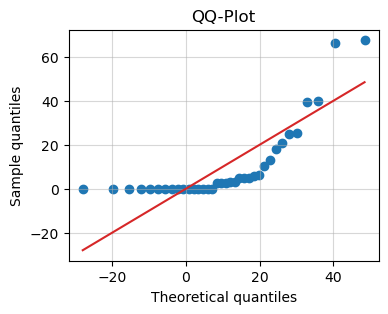

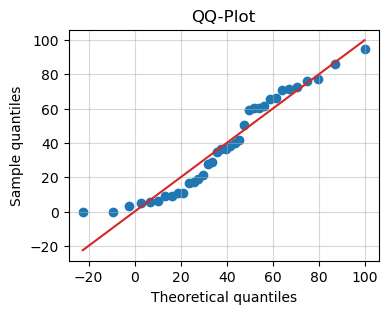

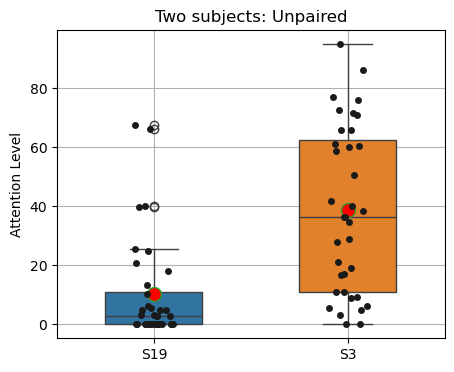

,SID,AgeGroup,Sex,Read,Write,Speak,Listen
2,S3,26 to 30,Male,4,4,4,4


,SID,AgeGroup,Sex,Read,Write,Speak,Listen
18,S19,31 to 35,Male,3,3,3,3


In [6]:
d1 = 93
d2 = 77
k = 1 + d1%25
p = 1 + d2%25
if p==k: p=p+1
print('your students are s{0} and s{1}'.format(k, p))

s19 = CD[CD['SID'] == 'S19']['AttentionScore']
s3 = CD[CD['SID'] == 'S3']['AttentionScore']

H0 = 'μ_S19 = μ_S3 : the mean attention score of S19 accross all conditions equals that of S3'
H1 = 'μ_S19 ≠ μ_S3 : the mean attention scores of S19 and S3 accross all conditions differ significantly'

stat1, p = stats.shapiro(s19)
print('S19 Shapiro Wilk Test Statistic:', stat1, '\n', 'S19 Shapiro Wilk p-value:', p)
stat2, p2 = stats.shapiro(s3)
print('S3 Shapiro Wilk Test Statistic:', stat2, '\n', 'S3 Shapiro Wilk p-value:', p2)
QQplot(s19)
QQplot(s3)

if p > 0.05 and p2 > 0.05:
    stat, p_val = stats.ttest_ind(s19, s3)
    print("Independent t-test:", stat, p_val)
else:
    stat, p_val = stats.mannwhitneyu(s19, s3, alternative='two-sided')
    print("Mann-Whitney U Test Statistic:", stat, '\n', "Mann-Whitney U p value:", p_val)

if p_val < 0.05:
    print("Since our p value is < 0.05, we reject the null hypothesis that {0}.".format(H0))
else:
    print("Since our p value is > 0.05, we fail to reject the null hypothesis that {0}.".format(H0))

fig, ax = plt.subplots(1, figsize=(5,4))
sp.stats.plot_groups_boxes([s19.values, s3.values], lines=False,
    xlabels=['S19', 'S3'], ylab='Attention Level', title='Two subjects: Unpaired', ax=ax)
plt.show()

display(DD[DD['SID']== 'S3'])
display(DD[DD['SID']== 'S19'])


After isolating our two students and their respective attention scores and stating our hypotheses, the Shapiro-Wilk test was conducted on both since the test is unpaired. Both returned p < 0.05 indicating non-normality, hence we used the Mann-Whitney U Test which returned p < 0.05, so we reject the null hypothesis. Hence confirming that S19 and S3 differ significantly in auditory attention accross all conditions. S3 averages around 40 with high variability whereas S19 consistently scores very low. S3's higher self-professed English level (4 vs 3) and younger age group (26-30 vs 31-35) could be contributing factors.

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[10 marks]</b></span>
    
#### Task 6. Compare two catogories of age 
<!-- [10 marks] -->

In this task, you will compare younger ($\leq 25$) and older ($> 25$) subjects to determine whether they differ in terms of auditory attention skills.

* Define your hypothesis clearly
* Acquire the data: Extract attention scores for younger subjects (up to 25) and older subjects (above 25)
* Explain the testing procedure (paired or unpaired, parametric or non-parametric, choice of test, assumptions, and any additional tests)
* Perform the tests
* Conclude your findings (**maximum 100 words**)

</div>

<br>

H₀: μ_younger = μ_older : mean attention scores do not differ between age groups
H₁: μ_younger ≠ μ_older : mean attention scores differ significantly between age groups
younger Shapiro Wilk Test Statistic: 0.9335937410301907 
 younger Shapiro Wilk p-value: 3.1528358965344677e-09
older Shapiro Wilk Test Statistic: 0.920559708304465 
 older Shapiro Wilk p-value: 5.711030066754719e-18
Mann-Whitney U Test Statistic: 81752.0 
 Mann-Whitney U p value: 0.9764151648047584
Since our p value is > 0.05, we fail to reject the null hypothesis that μ_younger = μ_older : mean attention scores do not differ between age groups.


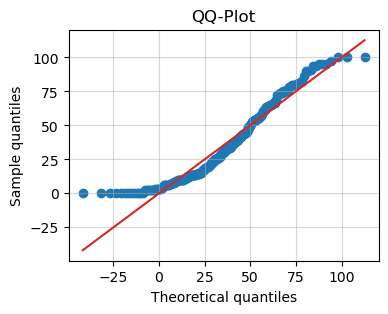

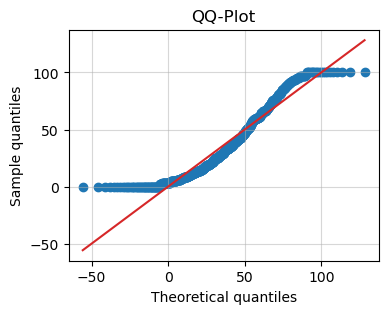

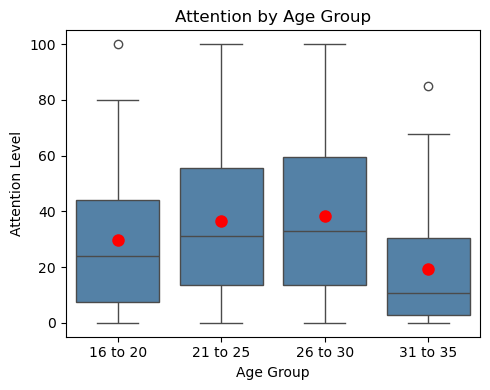

In [7]:

younger = CD_demo[CD_demo['AgeGroup'].isin(['16 to 20', '21 to 25'])]['AttentionScore']
older = CD_demo[CD_demo['AgeGroup'].isin(['26 to 30', '31 to 35'])]['AttentionScore']

H0 = 'μ_younger = μ_older : mean attention scores do not differ between age groups'
H1 = 'μ_younger ≠ μ_older : mean attention scores differ significantly between age groups'
print('H₀:', H0)
print('H₁:', H1)

stat1, p = stats.shapiro(younger)
print('younger Shapiro Wilk Test Statistic:', stat1, '\n', 'younger Shapiro Wilk p-value:', p)
stat2, p2 = stats.shapiro(older)
print('older Shapiro Wilk Test Statistic:', stat2, '\n', 'older Shapiro Wilk p-value:', p2)
QQplot(younger)
QQplot(older)

if p > 0.05 and p2 > 0.05:
    stat, p_val = stats.ttest_ind(younger, older)
    print("Independent t-test:", stat, p_val)
else:
    stat, p_val = stats.mannwhitneyu(younger, older, alternative='two-sided')
    print("Mann-Whitney U Test Statistic:", stat, '\n', "Mann-Whitney U p value:", p_val)

if p_val < 0.05:
    print("Since our p value is < 0.05, we reject the null hypothesis that {0}.".format(H0))
else:
    print("Since our p value is > 0.05, we fail to reject the null hypothesis that {0}.".format(H0))


fig, ax = plt.subplots(1, figsize=(5,4))
sns.boxplot(data=CD_demo, x='AgeGroup', y='AttentionScore',
            order=['16 to 20', '21 to 25', '26 to 30', '31 to 35'],
            color='steelblue', ax=ax,
            showmeans=True,
            meanprops={'marker':'o', 'markerfacecolor':'red',
                       'markeredgecolor':'red', 'markersize': 8})
ax.set_title('Attention by Age Group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Attention Level')
plt.tight_layout()
plt.show()


Both groups are non-normal (younger p=3.15×10⁻⁹, older p=5.71×10⁻¹⁸), so we use the unpaired Mann-Whitney U test. The test returns p=0.976, which is > 0.05, so we fail to reject the null hypothesis. There is no significant difference in auditory attention between younger (16-25) and older (26-35) participants. The boxplot confirms this. The lower mean of the 31-35 group and higher mean of the 26-30 group cancel out when combined, resulting in both age groups averaging to roughly the same position, suggesting age is not a significant factor in auditory attention performance within this sample.

<span style="float:left;color:gray;font-size:20px">Inferential Statistics: Association (correlation/regression)</span>
<br>

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[10 marks]</b></span>

#### Task 7. Find associations of variables 

In this task you will find if there is any significant association between any variables. The choice of variables are entrirely upto you. From attention score data file, we have, noise-level, semanticity, length of stimuli, attention score, and from demographic data file, we have sex, age-group and self reported English level skills. 

One of the most obviouse pair of variable is noise-level and attention score (as reported in the paper [[3]](#ref3))


**7.1** Select first pair of variable that make sense to compare **[5 marks]**
* Define your hypothesis clearly
* Explain the testing procedure (parametric/non-parameteric, which test, assumptions)
* Perform tests
* Conclude your findings (**in max 100 words**)

**7.2** Select second pair of variable that make sense to compare **[5 marks]**
* Define your hypothesis clearly
* Explain the testing procedure (parametric/non-parameteric, which test, assumptions)
* Perform tests
* Conclude your findings (**in max 100 words**)


<!-- [10 marks] -->

</div>

<br>

#### Q7.1

H₀: ρ = 0 : there is no association between length of stimuli and attention score
H₁: ρ ≠ 0 : there is a significant association between length of stimuli and attention score
Spearman correlation coefficiant (ρ): -0.2262925588114151
p-value: 6.481976147017581e-12
Since our p value is < 0.05, we reject the null hypothesis that ρ = 0 : there is no association between length of stimuli and attention score.


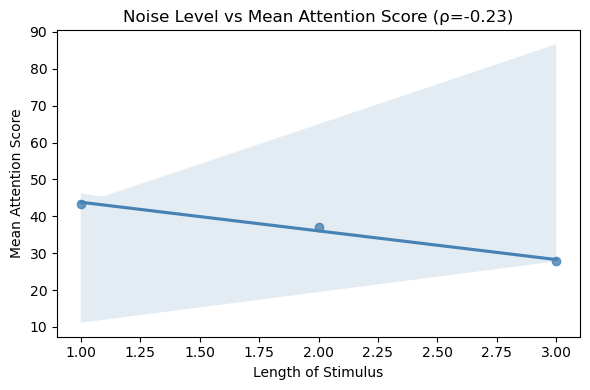

In [8]:

H0 = 'ρ = 0 : there is no association between length of stimuli and attention score'
H1 = 'ρ ≠ 0 : there is a significant association between length of stimuli and attention score'
print('H₀:', H0)
print('H₁:', H1)

CD['LengthStim_num'] = CD['LengthStim'].map({'L1': 1, 'L2': 2, 'L3': 3})

ρ, p_val = stats.spearmanr(CD['LengthStim_num'], CD['AttentionScore'])
print('Spearman correlation coefficiant (ρ):', ρ)
print('p-value:', p_val)

if p_val < 0.05:
    print("Since our p value is < 0.05, we reject the null hypothesis that {0}.".format(H0))
else:
    print("Since our p value is > 0.05, we fail to reject the null hypothesis that {0}.".format(H0))

fig, ax = plt.subplots(figsize=(6, 4))

length_means = CD.groupby('LengthStim_num')['AttentionScore'].mean().reset_index()
sns.regplot(data=length_means, x='LengthStim_num', y='AttentionScore', color='steelblue', ax=ax)
ax.set_title(f'Noise Level vs Mean Attention Score (ρ={ρ:.2f})')
ax.set_xlabel('Length of Stimulus')
ax.set_ylabel('Mean Attention Score')
plt.tight_layout()
plt.show()




I chose to explore the correlation between length of stimulus and attention score. Since the length of stimulus is an ordinal categorical normality cannot be assumed so we don't need to run shapiro wilk and automatically go for Spearman correlation. Out spearman correlation test returns a ρ value of - o.23 indicating weak negative correlation but none the less still a correlation. As expected as the length of the stimulus increases attention score reduces.



#### Q7.2

H₀: ρ = 0 : there is no association between self-reported English proficiency and attention score
H₁: ρ ≠ 0 : there is a significant association between self-reported English proficiency and attention score
Read: ρ=0.454, p=0.0226
  → Reject H0 for Read
Write: ρ=0.369, p=0.0695
  → Fail to reject H0 for Write
Speak: ρ=0.364, p=0.0739
  → Fail to reject H0 for Speak
Listen: ρ=0.299, p=0.1461
  → Fail to reject H0 for Listen
Since our p value is > 0.05, we fail to reject the null hypothesis that ρ = 0 : there is no association between self-reported English proficiency and attention score.


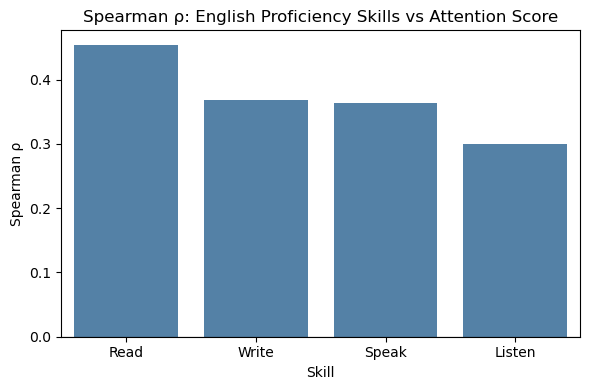

In [9]:
H0 = 'ρ = 0 : there is no association between self-reported English proficiency and attention score'
H1 = 'ρ ≠ 0 : there is a significant association between self-reported English proficiency and attention score'
print('H₀:', H0)
print('H₁:', H1)

participant_means = CD_demo.groupby('SID')[['AttentionScore', 'Read', 'Write', 'Speak', 'Listen']].mean().reset_index()


for skill in ['Read', 'Write', 'Speak', 'Listen']:
    r, p_val = stats.spearmanr(participant_means[skill], participant_means['AttentionScore'])
    print(f'{skill}: ρ={r:.3f}, p={p_val:.4f}')
    if p_val < 0.05:
        print(f"  → Reject H0 for {skill}")
    else:
        print(f"  → Fail to reject H0 for {skill}")

if p_val < 0.05:
    print("Since our p value is < 0.05, we reject the null hypothesis that {0}.".format(H0))
else:
    print("Since our p value is > 0.05, we fail to reject the null hypothesis that {0}.".format(H0))

skills = ['Read', 'Write', 'Speak', 'Listen']
spearman_ρ = [stats.spearmanr(participant_means[skill], participant_means['AttentionScore'])[0] for skill in skills]

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=skills, y=spearman_ρ , color='steelblue', ax=ax)
ax.set_title('Spearman ρ: English Proficiency Skills vs Attention Score')
ax.set_xlabel('Skill')
ax.set_ylabel('Spearman ρ')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()




For my second pair explored the correlation between self-reported English proficiency and mean attention score, split across four skills. Since proficiency only takes discrete values (1-5), normality cannot be assumed and Spearman is justified directly. Reading has the strongest association (ρ=0.45, p=0.023) and is the only skill to reach the significance level of p<0.05, while listening is weakest (ρ=0.30, p=0.146). This is counterintuitive given the auditory nature of the task, suggesting either that self reported proficiency is not a reliable measure of true ability, or that general literacy (reading) competence matters more than auditory skill specifically. This is explored further in Task 8.


<span style="float:left;color:gray;font-size:20px">New Exploration</span>
<br>

<div style="padding: 10px; border: 1px dashed black;">
<span style="float:right;font-size:16px"><b>[25 marks]</b></span>
    
#### Task 8 Your own exploration
<!-- [25 marks] -->

In this task, you will independently explore the dataset and experiment. By this stage, you should have a strong understanding of both the study and the data. This section gives you an opportunity to be creative and apply your knowledge. You may choose which aspects of the dataset to analyse, what questions to investigate, and which methods to use.

**Ensure that your analysis is conducted rigorously, and present your findings in a concise and well-structured report.**

*We strongly encourage you to treat this as an opportunity to produce something interesting and potentially publishable. If you believe your findings are novel and would like support in developing a publishable report, we would be happy to discuss this with you after you have completed your assessment.*
</div>

## Task 8: Does L1 Linguistic Distance from English Predict Auditory Attention?

As seen in section 7, self reported English proficiency showed only a weak association with attention score, suggesting it is not a reliable measure of true language capability. This motivated a deeper exploration of participants' linguistic backgrounds, specifically whether the structural distance between their first language (L1) and English predicts auditory attention performance.

To quantify language distance objectively, this task uses URIEL, an established typological knowledge base providing normalised vector representations of languages drawn from databases including WALS (Dryer and Haspelmath, 2013), PHOIBLE (Moran et al., 2014), Ethnologue (Lewis et al., 2015), and Glottolog (Hammarstrom et al., 2015). lang2vec is the Python interface to URIEL [7], providing pre-computed distance measures across six dimensions: phonological, syntactic, genetic, geographic, inventory, and featural. Where data is sparse, lang2vec uses k-nearest-neighbours (KNN) classification to predict missing typological features based on genetic, geographical, and feature based proximity.

I am most interested in exploring the phonological distance. Research on second language speech perception suggests that performance in noisy conditions is driven primarily by phonological competence rather than lexical, grammatical, or cognitive factors [8]. After the first year of life, the brain becomes neurally committed to the acoustic properties of its L1, meaning participants whose native sound system differs more from English must perform additional phoneme mapping work, a cognitive load that is likely amplified under noise [9]. The phonetic inventory distance measure is also considered, as non native listeners frequently struggle with vowel shifts and inventory differences specific to their L1 [9].



#### Data loading and lang2vec setup

In [10]:
extended_demographic_data = pd.read_csv('PhyAAt_Demographic_Rating_v2.csv')
ED = pd.DataFrame(extended_demographic_data)
ED.head()
LD = ED[['SID','First Language', 'Nationality']]
unique_combinations = LD[['First Language', 'Nationality','SID']].drop_duplicates()
display(unique_combinations)


# Install latest lang2vec directly from GitHub — the PyPI version is outdated 
# and does not include the distance() function
!pip install git+https://github.com/antonisa/lang2vec.git --break-system-packages

import lang2vec.lang2vec as l2v
import lang2vec
import shutil, os

# Copy pre computed distance file into the lang2vec data directory
# This file is required for phonological, syntactic, genetic etc. distance calculations
# and is not included in the standard installation
lang2vec_path = os.path.dirname(lang2vec.__file__)
shutil.copy(
    '/home/jovyan/stats lab report/distances2.zip',
    os.path.join(lang2vec_path, 'data', 'distances2.zip')
)
print('Setup complete. Files:', os.listdir(os.path.join(lang2vec_path, 'data')))

# ISO 639-3 codes per participant
# Note: Arabic varieties mapped to dialect-specific codes (ary=Moroccan, arq=Algerian, apc=Levantine)
# Farsi standard code is fas but lang2vec uses pes (Western Farsi)
lang_map = {
    'S1':'apc','S2':'mar','S3':'tam','S4':'mal','S5':'mal','S6':'mal',
    'S7':'tel','S8':'arq','S9':'pes','S10':'mal','S11':'apc','S12':'kaz',
    'S13':'apc','S14':'pes','S15':'ita','S16':'pes','S17':'ita','S18':'mai',
    'S19':'ita','S20':'apc','S21':'urd','S22':'apc','S23':'ary','S24':'ita','S25':'kan'
}
ED['LangCode'] = ED['SID'].map(lang_map)

,First Language,Nationality,SID
0,Arabic,Lebanese,S1
1,Marathi,Indian,S2
2,Tamil,Indian,S3
3,Malayalam,Indian,S4
4,Malayalam,Indian,S5
5,Malayalam,Indian,S6
6,Telgu,Indian,S7
7,Arabic,Algerian,S8
8,Farsi,Iranian,S9
9,Malayalam,Indian,S10


Defaulting to user installation because normal site-packages is not writeable
  Cloning https://github.com/antonisa/lang2vec.git to /tmp/pip-req-build-c2wl2wl3
  Running command git clone --filter=blob:none --quiet https://github.com/antonisa/lang2vec.git /tmp/pip-req-build-c2wl2wl3
  Resolved https://github.com/antonisa/lang2vec.git to commit 82ab4457ae3a45f552b8d70310ac2a259b44c62a
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Setup complete. Files: ['GENETIC.csv', 'distances_languages.txt', 'family_features.npz', 'FEATURAL.csv', 'distances2.zip', 'INVENTORY.csv', 'feature_averages.npz', 'feature_predictions.npz', 'PHONOLOGICAL.csv', 'geocoord_features.npz', '__MACOSX', 'features.npz', 'letter_codes.json', 'learned.npy', 'GEOGRAPHIC.csv', 'SYNTACTIC.csv', 'distances.zip']



As we can see our unqiue languages are 'Arabic', 'Marathi', 'Tamil', 'Malayalam', 'Telgu', 'Farsi', 'Kazakh', 'Italian', 'Mathili', 'Urdu' and 'Kannada'. However upon looking closer we can see Arabic is listen 3 times but with different nationalities, Lebanese, Moroccan and Algerian. Geographically, modern Arabic varieties are classified into five groups: Maghrebi, Egyptian (including Egyptian and Sudanese), Mesopotamian, Levantine and Peninsular Arabic[5]. Lebanese arabic comes under the levantine groups with more french influence where as Moroccan and Algerian arabic come under the magrehebi group with more influence from Berber and Spanish and as we can see these langauge differences are accounted for in Python ISO codes and hence should be delt with accordingly[6].


###  General Correlation: All Distance Types vs Mean Attention Score

Each of the six distance type available in Lang2vec are correlated against each participant's mean attention score across all conditions (n=25). This establishes whether any distance measure predicts overall attention performance before checking in regards to noise level.

H₀: ρ = 0 : there is no association between phonological distance from English and mean attention score
H₁: ρ ≠ 0 : there is a significant association between phonological distance from English and mean attention score

Spearman ρ=-0.091, p=0.6638
Since p > 0.05, we fail to reject the null hypothesis that ρ = 0 : there is no association between phonological distance from English and mean attention score.


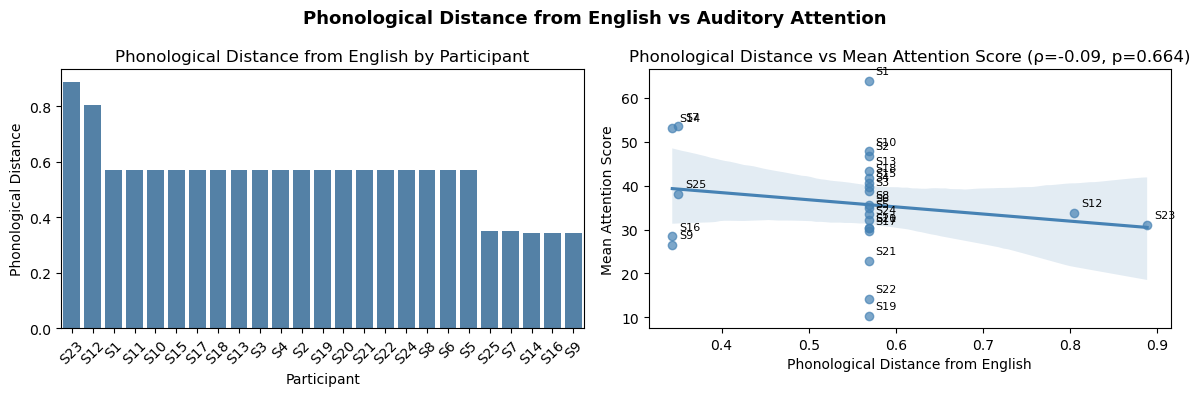


Other distance types (same H0/H1 framework):
syntactic: ρ=0.251, p=0.2254 → fail to reject H0
genetic: ρ=0.226, p=0.2764 → fail to reject H0
geographic: ρ=0.406, p=0.0443 → reject H0
inventory: ρ=-0.135, p=0.5194 → fail to reject H0
featural: ρ=-0.001, p=0.9968 → fail to reject H0


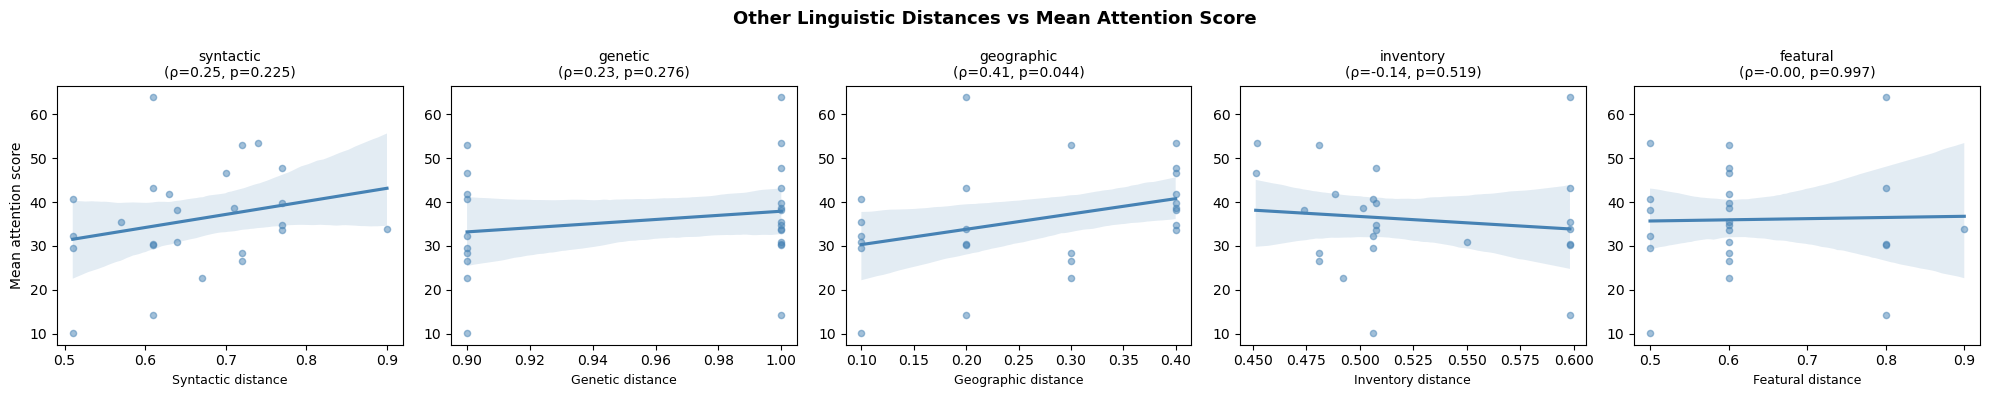

In [13]:
# phonological distance per participant 

participant_means = CD.groupby('SID')['AttentionScore'].mean().reset_index()
participant_means = participant_means.merge(ED[['SID', 'LangCode']], on='SID')

participant_means['phonological'] = participant_means['LangCode'].apply(
    lambda x: l2v.distance('phonological', x, 'eng'))

H0 = 'ρ = 0 : there is no association between phonological distance from English and mean attention score'
H1 = 'ρ ≠ 0 : there is a significant association between phonological distance from English and mean attention score'
print('H₀:', H0)
print('H₁:', H1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ed_sorted = participant_means.sort_values('phonological', ascending=False)
sns.barplot(data=ed_sorted, x='SID', y='phonological', color='steelblue', ax=axes[0])
axes[0].set_title('Phonological Distance from English by Participant')
axes[0].set_xlabel('Participant')
axes[0].set_ylabel('Phonological Distance')
axes[0].tick_params(axis='x', rotation=45)

r_phon, p_phon = stats.spearmanr(participant_means['phonological'], participant_means['AttentionScore'])
print(f'\nSpearman ρ={r_phon:.3f}, p={p_phon:.4f}')

if p_phon < 0.05:
    print(f"Since p < 0.05, we reject the null hypothesis that {H0}.")
else:
    print(f"Since p > 0.05, we fail to reject the null hypothesis that {H0}.")

sns.regplot(data=participant_means, x='phonological', y='AttentionScore',
            color='steelblue', ax=axes[1], scatter_kws={'alpha': 0.7})
for _, row in participant_means.iterrows():
    axes[1].annotate(row['SID'], (row['phonological'], row['AttentionScore']),
                     textcoords='offset points', xytext=(5, 5), fontsize=8)
axes[1].set_title(f'Phonological Distance vs Mean Attention Score (ρ={r_phon:.2f}, p={p_phon:.3f})')
axes[1].set_xlabel('Phonological Distance from English')
axes[1].set_ylabel('Mean Attention Score')
plt.suptitle('Phonological Distance from English vs Auditory Attention', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# remaining 5 distance types — same hypothesis framework applied for comparison
print('\nOther distance types (same H0/H1 framework):')
other_distances = ['syntactic', 'genetic', 'geographic', 'inventory', 'featural']
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, dist in zip(axes, other_distances):
    participant_means[dist] = participant_means['LangCode'].apply(
        lambda x: l2v.distance(dist, x, 'eng'))
    r, p_val = stats.spearmanr(participant_means[dist], participant_means['AttentionScore'])
    sns.regplot(data=participant_means, x=dist, y='AttentionScore',
                color='steelblue', ax=ax, scatter_kws={'alpha': 0.5, 's': 20})
    ax.set_title(f'{dist}\n(ρ={r:.2f}, p={p_val:.3f})', fontsize=10)
    ax.set_xlabel(f'{dist.capitalize()} distance', fontsize=9)
    ax.set_ylabel('Mean attention score' if ax == axes[0] else '')
    result = 'reject H0' if p_val < 0.05 else 'fail to reject H0'
    print(f'{dist}: ρ={r:.3f}, p={p_val:.4f} → {result}')
plt.suptitle('Other Linguistic Distances vs Mean Attention Score', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Our spearman test for phonological distance returned a ρ value of −0.12 . Looking at the scatter plot the points are scattered with no obvious trend and there is no clear relationship between average attention score and phonological distance of L2 from L1.  We can see from the distance bar chart that Arabic speakers (S1, S22, S23, S20) have the highest phonological distance from English (~0.9) while Italian and Farsi speakers have the lowest (~0.35). Despite this, attention scores don't follow this pattern. S1 (Arabic, distance=0.9) actually has one of the highest attention scores.  This null result suggests that other factors such as motivation, English exposure and individual language ability matter more. 


Since lang2vec also offers 5 more types of distances I though it would be worth exploring all of them as well. The results are seen above. Interestingly the only significance ρ value where we reject the H0 is that of geographic distance. However we must intereperet this value cautiously as geographic distance in Lang2Vec just measures physical distance between where languages are spoken, and hence doesn’t represent any direct linguistic or cognitive features relevant in an auditory attention task. As we know correlation is not necessarily causation. This result is likely a proxy for something. For example perhaps participants from geographically closer regions (Europe) may have had more English exposure, better schooling in English, or more cultural familiarity. 

To conclude, none of the linguistic distance measures significantly predict or affect auditory attention. These null findings could also be affected by the limited statistical power of a sample size of only 25. Furthermore, even though the PhyAAt study controls for the fact that all participants are non-native English speakers, it does not standardise the participants years of english study, country of residence or daily english usage/exposure.So even if two participants have the same L1 phonological distance from English, one might have had 10 years of immersion and another only classroom learning, this  would impact attention score more.


### 8.2 Does Phonological Distance Matter More Under Noise?

Overall the previous Spearman test showed no significant relationship between phonological distance and attention across all conditions. However in our task 2 data exploration we can see that noise is the strongest predictor of attention so the question becomes whether phonological distance moderates this effect specifically under adverse conditions. To do this Spearman ρ is computed separately at each SNR level (n=25 per level) so we can track whether the relationship strengthens as noise increases.


SNR=-6dB: ρ=-0.433, p=0.0305
SNR=-3dB: ρ=-0.169, p=0.4200
SNR=0dB: ρ=-0.173, p=0.4092
SNR=3dB: ρ=-0.189, p=0.3663
SNR=6dB: ρ=-0.137, p=0.5148


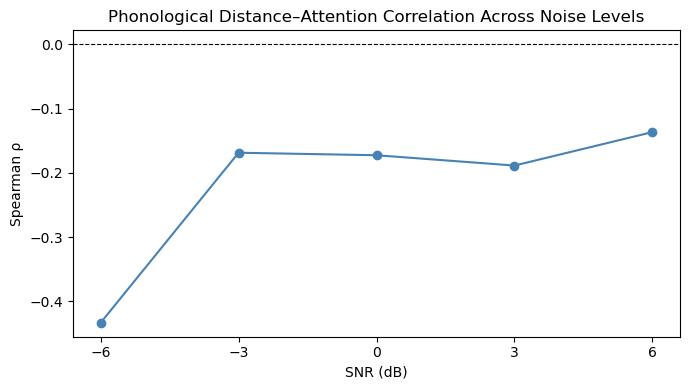

In [17]:
CD_ling = CD.merge(participant_means[['SID', 'phonological']], on='SID')

correlations = []
for snr in [-6, -3, 0, 3, 6]:
    subset = CD_ling[CD_ling['SNRdB']==snr].groupby('SID')['AttentionScore'].mean().reset_index()
    subset = subset.merge(participant_means[['SID','phonological']], on='SID')
    r, p = stats.spearmanr(subset['phonological'], subset['AttentionScore'])
    correlations.append({'SNR': snr, 'rho': r, 'p': p})
    print(f'SNR={snr}dB: ρ={r:.3f}, p={p:.4f}')

corr_df = pd.DataFrame(correlations)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(corr_df['SNR'], corr_df['rho'], marker='o', color='steelblue')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Phonological Distance–Attention Correlation Across Noise Levels')
ax.set_xlabel('SNR (dB)')
ax.set_ylabel('Spearman ρ')
ax.set_xticks([-6, -3, 0, 3, 6])
plt.tight_layout()
plt.show()

At SNR=−6dB (the noisiest condition) ρ=−0.32, the strongest negative correlation, suggesting participants with more phonologically distant L1s score lower under the worst noise. The correlation weakens as noise reduces, approaching zero at SNR=6dB. The trend is not perfectly monotonic as SNR=−3dB shows a weaker effect than expected, likely reflecting natural variability within n=25. None of the individual correlations reach p<0.05, meaning we cannot rule out chance. However the directional pattern is consistent across all noise levels, suggesting a real but small effect that the sample size is insufficient to detect statistically.

### 8.3 High vs Low Phonological Distance Groups
For further exploration, participants are split at the median phonological distance into two groups to visualise whether the difference in attention scores between them is meaningful in practice. Mean attention is compared across noise levels in the line plot, and a Mann-Whitney U (non-parametric, unpaired, two-tailed) test is run specifically at SNR=−6dB, the condition where ρ was strongest, to formally test whether the groups differ in the nosiest condition. Since Mann-Whitney U is rank-based and attention scores are non-normal, rank-biserial r is used as the effect size instead of Cohen's d. It measures how consistently one group outranks the other independent of sample size, making it appropriate when n is small.

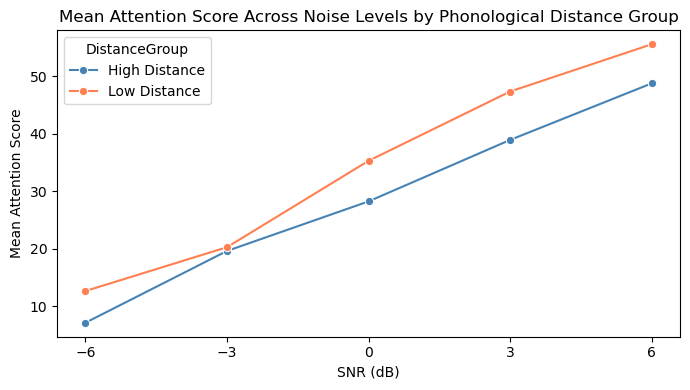

Mann-Whitney U: stat=1191.0, p=0.0039
Rank-biserial r (effect size): 0.338


In [18]:
median_dist = participant_means['phonological'].median()
CD_ling['DistanceGroup'] = CD_ling['SID'].map(
    lambda x: 'High Distance' 
    if participant_means.loc[participant_means['SID']==x,'phonological'].values[0] >= median_dist
    else 'Low Distance')

group_snr = CD_ling[CD_ling['SNRdB']!=1000].groupby(
    ['SNRdB','DistanceGroup'])['AttentionScore'].mean().reset_index()

fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=group_snr, x='SNRdB', y='AttentionScore',
             hue='DistanceGroup', marker='o', ax=ax,
             palette={'High Distance':'steelblue','Low Distance':'coral'})
ax.set_title('Mean Attention Score Across Noise Levels by Phonological Distance Group')
ax.set_xlabel('SNR (dB)')
ax.set_ylabel('Mean Attention Score')
ax.set_xticks([-6,-3,0,3,6])
plt.tight_layout()
plt.show()

high = CD_ling[(CD_ling['SNRdB']==-6)&(CD_ling['DistanceGroup']=='High Distance')]['AttentionScore']
low  = CD_ling[(CD_ling['SNRdB']==-6)&(CD_ling['DistanceGroup']=='Low Distance')]['AttentionScore']
stat, p = stats.mannwhitneyu(high, low, alternative='two-sided')
n1, n2 = len(high), len(low)
r_rb = 1 - (2*stat)/(n1*n2)
print(f'Mann-Whitney U: stat={stat:.1f}, p={p:.4f}')
print(f'Rank-biserial r (effect size): {r_rb:.3f}')

While the Spearman correlation in 8.2 suggested the relationship between phonological distance and attention strengthens under noise (ρ=−0.32 at SNR=−6), the Mann-Whitney U test at SNR=−6dB confirms this difference is statistically significant (p=0.0039). The rank-biserial effect size of r=0.338 indicates a small to medium practical effect. The line plot however shows the mean difference between high and low distance groups remains relatively stable across all noise levels, suggesting phonological distance has a consistent general effect on attention rather than one specific to adverse listening conditions. 

### 8.4 Conclusion

To conclude, task 8 explored whether L1 phonological distance from English predicts auditory attention using objective distance measures from the URIEL typological database via lang2vec [7]. No distance type significantly predicted overall attention, though geographic distance showed a marginal effect likely confounded by English exposure rather than reflecting a true linguistic effect. When examined across noise levels, phonological distance showed a consistent negative trend strongest at SNR=−6dB (ρ=−0.32), and the Mann-Whitney U test at SNR=−6dB returned p=0.0039 with a small to medium effect (rank-biserial r=0.338), confirming the groups differ significantly under the noisiest condition. The line plot suggests this advantage for low distance participants persists consistently across all noise levels, indicating phonological distance may reflect a general attention advantage rather than one specific to adverse listening conditions. Stronger conclusions require larger exposure controlled samples.

Future work in this line of reasearch could consider adopting a  framework for categorising participants based on their immersion and exposure levels [9].  Accent familiarity could also be considered as an additional variable given the dataset uses a single male speaker (accent of male speaker is unknown) throughout. 




**References**:


- <span id="ref1">[1]. PhyAAt project page: https://PhyAAt.github.io</span>
- <span id="ref2">[2]. Bajaj, N., Carrión, J. R., Bellotti, F., Berta, R., & De Gloria, A. (2021). Analysis of factors affecting the auditory attention of non-native speakers in e-learning environments. Electronic Journal of e-Learning, 19, 159-169.  https://doi.org/10.34190/ejel.19.3.2296</span>
- <span id="ref3">[3]. Bajaj, N., Carrión, J. R., & Bellotti, F. (2020). Phyaat: Physiology of auditory attention to speech dataset. arXiv preprint arXiv:2005.11577. https://arxiv.org/pdf/2005.11577</span>
- <span id="ref3"> [4] T. Ho, "Tatoeba Project," 2006. https://tatoeba.org</span>
-   <span id="ref3"> [5]Hooshmand, Dana. "Arabic Dialects Compared: Maghrebi, Egyptian, Levantine, Hejazi, Gulf, and MSA". Discover Discomfort. https://discoverdiscomfort.com/arabic-dialects-maghrebi-egyptian-levantine-gulf-hejazi-msa/</span>
-  <span id="ref3">  [6] SIL International, "ISO 639-3 Code: ara — Arabic," ISO 639-3 Registration Authority, 2024. [Online]. Available: https://iso639-3.sil.org/code/ara</span>
- <span id="ref3"> [7] P. Littell et al., "URIEL and lang2vec: Representing languages as typological, geographical, and phylogenetic vectors," in *Proc. EACL*, 2017, pp. 8–14 https://aclanthology.org/E17-2.pdf</span>
- <span id="ref3"> [8] Bovo, R., Lovo, E., Astolfi, L., Montino, S., Franchella, S., Gallo, S., Prodi, N., Borsetto, D. and Trevisi, P. (2018) 'Speech perception in noise by young sequential bilingual children', Acta Otorhinolaryngologica Italica, 38, pp. 536-543. doi: 10.14639/0392-100X-1846</span> 
 
- <span id="ref3"> [9] Hui, C.T.J., Masuda, H., Osawa, E., Arai, T ., Watson, C.I. and Hioka, Y. (2025) 'Role of language familiarity in understanding speech in noise under various acoustic environments', Speech Communication, 169, 103195. Available at: https://doi.org/10.1016/j.specom.2025.103195</span>
- <span id="ref3">[10] A. Anastasopoulos, "lang2vec," GitHub, 2019. [Online]. Available: https://github.com/antonisa/lang2vec</span>
 

